# SQL analytics and relational database design
Three SQLite exercises, each beyond basic `SELECT`:

1. **World Factbook:** joins, CTEs and window functions on countries and cities (density, growth, urban concentration), plus data-quality checks.
2. **College majors (ACS 2010-2012):** earnings, unemployment and gender composition by major, with percentiles and rankings computed in SQL.
3. **Database design:** normalising a 161-column, one-row-per-game baseball log (Retrosheet, 2010-2016) into a relational schema with primary and foreign keys and an appearance table, then proving integrity with SQL.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import sqlite3
def q(sql, con): return pd.read_sql(sql, con)
fb = sqlite3.connect("data/factbook.db"); cm = sqlite3.connect("data/college_majors.db")
q("SELECT name, sql FROM sqlite_master WHERE type='table'", fb)

,name,sql
0,sqlite_sequence,"CREATE TABLE sqlite_sequence(name,seq)"
1,facts,"CREATE TABLE ""facts"" (""id"" INTEGER PRIMARY KEY..."
2,cities,CREATE TABLE cities (\n id integer prim...


## 1. World Factbook

In [2]:
q("""SELECT COUNT(*) AS rows, SUM(population IS NULL) AS missing_pop, SUM(area_land IS NULL OR area_land = 0) AS missing_area,
        SUM(population_growth > 5) AS growth_over_5pct, MAX(population) AS max_pop
     FROM facts""", fb)

,rows,missing_pop,missing_area,growth_over_5pct,max_pop
0,261,19,16,0,7256490011


In [3]:
q("""
WITH c AS (SELECT name, population, area_land, population * 1.0 / area_land AS density, population_growth,
                  birth_rate - death_rate + migration_rate AS implied_growth_per_1000
           FROM facts WHERE area_land > 0 AND population > 1000000 AND name <> 'World')
SELECT name, population, ROUND(density, 0) AS people_per_km2, population_growth AS growth_pct,
       ROUND(implied_growth_per_1000 / 10, 2) AS implied_growth_pct,
       RANK() OVER (ORDER BY density DESC) AS density_rank
FROM c ORDER BY density DESC LIMIT 10""", fb)

,name,population,people_per_km2,growth_pct,implied_growth_pct,density_rank
0,Singapore,5674472,8260.0,1.89,1.89,1
1,Hong Kong,7141106,6655.0,0.38,0.38,2
2,Gaza Strip,1869055,5192.0,2.81,2.81,3
3,Bahrain,1346613,1772.0,2.41,2.41,4
4,Bangladesh,168957745,1298.0,1.60,1.60,5
5,Taiwan,23415126,726.0,0.23,0.23,6
6,Mauritius,1339827,660.0,0.64,0.64,7
7,Lebanon,6184701,605.0,0.86,1.08,8
8,Rwanda,12661733,513.0,2.56,2.56,9
9,"Korea, South",49115196,507.0,0.14,0.14,10


In [4]:
urban = q("""
WITH city_tot AS (SELECT facts_id, SUM(population) AS city_pop, MAX(population) AS biggest_city,
                         MAX(CASE WHEN capital = 1 THEN name END) AS capital FROM cities GROUP BY facts_id)
SELECT f.name AS country, f.population, ct.capital, ROUND(100.0 * ct.biggest_city / f.population, 1) AS biggest_city_share_pct,
       ROUND(100.0 * ct.city_pop / f.population, 1) AS listed_cities_share_pct
FROM facts f JOIN city_tot ct ON ct.facts_id = f.id
WHERE f.population > 5000000 ORDER BY biggest_city_share_pct DESC LIMIT 10""", fb)
urban

,country,population,capital,biggest_city_share_pct,listed_cities_share_pct
0,Israel,8049314,Jerusalem,42.0,64.9
1,Chile,17508260,Santiago,34.5,43.9
2,United Arab Emirates,5779760,Abu Dhabi,34.2,67.5
3,Lebanon,6184701,Beirut,32.7,32.7
4,Greece,10775643,Athens,31.7,39.9
5,Paraguay,6783272,Asuncion,31.5,31.5
6,Argentina,43431886,Buenos Aires,31.1,43.6
7,Japan,126919659,Tokyo,29.3,47.3
8,Portugal,10825309,Lisbon,26.3,38.9
9,El Salvador,6141350,San Salvador,26.1,26.1


In [5]:
check = q("""SELECT f.name, f.population, SUM(c.population) AS city_pop FROM facts f JOIN cities c ON c.facts_id = f.id
             GROUP BY f.id HAVING SUM(c.population) > f.population""", fb)
print("countries whose listed cities exceed the national population (data-quality flag):"); check

countries whose listed cities exceed the national population (data-quality flag):


,name,population,city_pop
0,American Samoa,54343,64000
1,Guam,161785,169000
2,Northern Mariana Islands,52344,56000


## 2. College majors: which degrees pay, and for whom?
**First, an audit.** The practice database from the course (`college_majors.db`) was edited during SQL exercises. Before analysing it, every row is compared with the published source (FiveThirtyEight `recent-grads.csv`, from the American Community Survey 2010-2012).

In [6]:
src = pd.read_csv("data/recent_grads_fivethirtyeight.csv")
prac = q("SELECT * FROM recent_grads", cm)
m = prac.merge(src, on="Major", suffixes=("_db", "_src"))
audit = {c: int((np.abs(m[c + "_db"] - m[c + "_src"]) > 1e-6).sum()) for c in ["Total", "Men", "Women", "ShareWomen", "Median", "Unemployment_rate"]}
print("rows that differ from the source, by column:", audit)
print("practice DB rows failing Men + Women = Total:", int(((prac.Men + prac.Women - prac.Total).abs() > 1).sum()), "of", len(prac))
cm = sqlite3.connect(":memory:"); src.to_sql("recent_grads", cm, index=False)   # analyse the verified source from here on

rows that differ from the source, by column: {'Total': 0, 'Men': 122, 'Women': 122, 'ShareWomen': 122, 'Median': 0, 'Unemployment_rate': 0}
practice DB rows failing Men + Women = Total: 123 of 173


173

In [7]:
cat = q("""
SELECT Major_category, COUNT(*) AS majors, SUM(Total) AS graduates,
       ROUND(SUM(Median * Total) * 1.0 / SUM(Total), 0) AS weighted_median_earnings,
       ROUND(SUM(Unemployed) * 100.0 / SUM(Employed + Unemployed), 1) AS unemployment_pct,
       ROUND(SUM(Women) * 100.0 / SUM(Total), 1) AS women_pct
FROM recent_grads WHERE Total IS NOT NULL GROUP BY Major_category ORDER BY weighted_median_earnings DESC""", cm)
cat

,Major_category,majors,graduates,weighted_median_earnings,unemployment_pct,women_pct
0,Engineering,29,5.376e+05,55979.0,6.6,24.0
1,Computers & Mathematics,11,2.990e+05,47351.0,7.2,30.2
2,Business,13,1.302e+06,40942.0,6.8,48.7
3,Health,12,4.632e+05,40611.0,5.6,83.7
4,Social Science,9,5.300e+05,39047.0,9.7,51.5
5,Physical Sciences,10,1.855e+05,38801.0,5.4,48.6
6,Law & Public Policy,5,1.791e+05,35729.0,8.5,49.1
7,Interdisciplinary,1,1.230e+04,35000.0,7.1,77.1
8,Agriculture & Natural Resources,9,7.562e+04,34952.0,5.2,46.6
9,Communications & Journalism,4,3.926e+05,34731.0,7.5,66.4


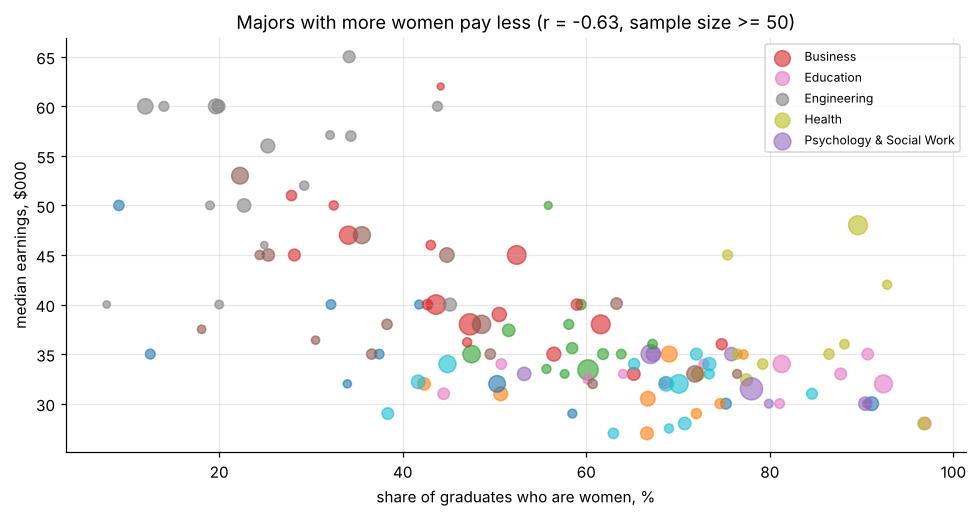

122 majors; each +10 percentage points of women is associated with $2,475 lower median earnings


,Major,Major_category,Median,P25th,P75th,women_pct,earnings_quartile,rank_in_category
0,CHEMICAL ENGINEERING,Engineering,65000,50000,75000,34.2,1,1
1,ACTUARIAL SCIENCE,Business,62000,53000,72000,44.1,1,1
2,MECHANICAL ENGINEERING,Engineering,60000,48000,70000,12.0,1,2
3,ELECTRICAL ENGINEERING,Engineering,60000,45000,72000,19.6,1,2
4,COMPUTER ENGINEERING,Engineering,60000,45000,75000,19.9,1,2
5,AEROSPACE ENGINEERING,Engineering,60000,42000,70000,14.0,1,2
6,BIOMEDICAL ENGINEERING,Engineering,60000,36000,70000,43.8,1,2
7,BIOLOGICAL ENGINEERING,Engineering,57100,40000,76000,32.1,1,7


In [8]:
top = q("""
SELECT Major, Major_category, Median, P25th, P75th, ROUND(ShareWomen * 100, 1) AS women_pct,
       NTILE(4) OVER (ORDER BY Median DESC) AS earnings_quartile,
       RANK() OVER (PARTITION BY Major_category ORDER BY Median DESC) AS rank_in_category
FROM recent_grads WHERE Sample_size >= 50 ORDER BY Median DESC LIMIT 8""", cm)
g = q("SELECT Major, Median, ShareWomen, Total, Sample_size, Major_category FROM recent_grads WHERE Sample_size >= 50 AND ShareWomen IS NOT NULL", cm)
r = np.corrcoef(g.ShareWomen, g.Median)[0, 1]
slope = np.polyfit(g.ShareWomen, g.Median, 1)[0]
fig, ax = plt.subplots(figsize=(9, 4.8))
for c, s in g.groupby("Major_category"):
    ax.scatter(100 * s.ShareWomen, s.Median / 1e3, s=np.sqrt(s.Total) / 3, alpha=.6, label=c if c in ["Engineering", "Education", "Health", "Business", "Psychology & Social Work"] else None)
ax.set_xlabel("share of graduates who are women, %"); ax.set_ylabel("median earnings, $000"); ax.legend(fontsize=8)
ax.set_title(f"Majors with more women pay less (r = {r:.2f}, sample size >= 50)")
plt.tight_layout(); plt.savefig(IMG / "majors_gender_pay.png", bbox_inches="tight"); plt.show()
print(f"{len(g)} majors; each +10 percentage points of women is associated with ${abs(slope) / 10:,.0f} lower median earnings")
top

## 3. Database design: from a 161-column log to a normalised schema
The raw game log repeats team names, park codes, umpires, managers and 18 starting players (id, name, position) across 161 columns on every row. A normalised design stores each fact once:

`person(person_id PK)` · `team(team_id PK)` · `park(park_id PK)` · `game(game_id PK, date, home/visiting team FK, park FK, scores, ...)` · `team_appearance(game_id FK, team_id FK, home, runs, hits, ...)` · `person_appearance(game_id FK, person_id FK, team_id FK, role, position)`

In [9]:
log = pd.read_csv("data/retrosheet_gamelogs_2010_2016.csv.gz", low_memory=False)
log["date"] = log["date"].astype(str)
print(f"{log.shape[0]:,} games x {log.shape[1]} columns, {log.memory_usage(deep=True).sum() / 1e6:.1f} MB")
db = sqlite3.connect(":memory:"); db.execute("PRAGMA foreign_keys = ON")
db.executescript("""
CREATE TABLE person (person_id TEXT PRIMARY KEY, first TEXT, last TEXT);
CREATE TABLE team (team_id TEXT PRIMARY KEY, league TEXT, city TEXT, nickname TEXT, franch_id TEXT);
CREATE TABLE park (park_id TEXT PRIMARY KEY, name TEXT, city TEXT, state TEXT);
CREATE TABLE game (game_id TEXT PRIMARY KEY, date TEXT, number_of_game INT, park_id TEXT REFERENCES park(park_id),
                   length_outs INT, day_night TEXT, attendance INT, length_minutes INT);
CREATE TABLE team_appearance (game_id TEXT REFERENCES game(game_id), team_id TEXT REFERENCES team(team_id), home INT,
                   league TEXT, score INT, hits INT, homeruns INT, walks INT, strikeouts INT, errors INT, PRIMARY KEY (game_id, team_id));
CREATE TABLE person_appearance (appearance_id INTEGER PRIMARY KEY, game_id TEXT REFERENCES game(game_id),
                   person_id TEXT REFERENCES person(person_id), team_id TEXT REFERENCES team(team_id), role TEXT, position INT);
""")
person = pd.read_csv("data/person_codes.csv").rename(columns={"id": "person_id"})[["person_id", "first", "last"]]
team = pd.read_csv("data/team_codes.csv").drop_duplicates("team_id")[["team_id", "league", "city", "nickname", "franch_id"]]
park = pd.read_csv("data/park_codes.csv")[["park_id", "name", "city", "state"]]
for name, df_ in [("person", person), ("team", team), ("park", park)]: df_.to_sql(name, db, if_exists="append", index=False)
log["game_id"] = log.h_name + log.date + log.number_of_game.astype(str)
log[["game_id", "date", "number_of_game", "park_id", "length_outs", "day_night", "attendance", "length_minutes"]].to_sql("game", db, if_exists="append", index=False)
ta = []
for side, home in (("h", 1), ("v", 0)):
    t = log[["game_id", f"{side}_name", f"{side}_league", f"{side}_score", f"{side}_hits", f"{side}_homeruns", f"{side}_walks", f"{side}_strikeouts", f"{side}_errors"]].copy()
    t.columns = ["game_id", "team_id", "league", "score", "hits", "homeruns", "walks", "strikeouts", "errors"]; t["home"] = home; ta.append(t)
pd.concat(ta).to_sql("team_appearance", db, if_exists="append", index=False)
pa = []
for side in ("h", "v"):
    for role, col in [("manager", f"{side}_manager_id"), ("starting_pitcher", f"{side}_starting_pitcher_id")] + [(f"starter", f"{side}_player_{k}_id") for k in range(1, 10)]:
        pos = log[f"{side}_player_{col.split('_')[2]}_def_pos"] if role == "starter" else np.nan
        pa.append(pd.DataFrame({"game_id": log.game_id, "person_id": log[col], "team_id": log[f"{side}_name"], "role": role, "position": pos}))
    pa.append(pd.DataFrame({"game_id": log.game_id, "person_id": log["hp_umpire_id"], "team_id": None, "role": "hp_umpire", "position": np.nan})) if side == "h" else None
pa = pd.concat(pa).dropna(subset=["person_id"])
pa.to_sql("person_appearance", db, if_exists="append", index=False)
sizes = q("SELECT 'game' t, COUNT(*) n FROM game UNION ALL SELECT 'team_appearance', COUNT(*) FROM team_appearance UNION ALL SELECT 'person_appearance', COUNT(*) FROM person_appearance", db)
sizes

17,007 games x 161 columns, 85.0 MB


,t,n
0,game,17007
1,team_appearance,34014
2,person_appearance,391161


In [10]:
integrity = q("""
SELECT 'orphan park' AS check_name, COUNT(*) AS n FROM game g LEFT JOIN park p USING (park_id) WHERE p.park_id IS NULL
UNION ALL SELECT 'orphan team', COUNT(*) FROM team_appearance ta LEFT JOIN team t USING (team_id) WHERE t.team_id IS NULL
UNION ALL SELECT 'orphan person', COUNT(*) FROM person_appearance pa LEFT JOIN person p USING (person_id) WHERE p.person_id IS NULL
UNION ALL SELECT 'games without exactly 2 teams', COUNT(*) FROM (SELECT game_id FROM team_appearance GROUP BY game_id HAVING COUNT(*) <> 2)
UNION ALL SELECT 'games without 9 starters per team', COUNT(*) FROM (SELECT game_id, team_id FROM person_appearance WHERE role='starter' GROUP BY 1, 2 HAVING COUNT(*) <> 9)""", db)
integrity

,check_name,n
0,orphan park,0
1,orphan team,0
2,orphan person,0
3,games without exactly 2 teams,0
4,games without 9 starters per team,0


In [11]:
mgr = q("""
WITH res AS (SELECT a.game_id, a.team_id, CASE WHEN a.score > b.score THEN 1 ELSE 0 END AS win
             FROM team_appearance a JOIN team_appearance b ON a.game_id = b.game_id AND a.team_id <> b.team_id)
SELECT p.first || ' ' || p.last AS manager, COUNT(*) AS games, ROUND(100.0 * SUM(r.win) / COUNT(*), 1) AS win_pct
FROM person_appearance pa JOIN res r ON r.game_id = pa.game_id AND r.team_id = pa.team_id JOIN person p USING (person_id)
WHERE pa.role = 'manager' GROUP BY pa.person_id HAVING COUNT(*) >= 800 ORDER BY win_pct DESC LIMIT 8""", db)
hr = q("""SELECT substr(g.date, 1, 4) AS season, ROUND(AVG(ta.homeruns), 2) AS hr_per_team_game, ROUND(AVG(ta.strikeouts), 2) AS so_per_team_game
          FROM team_appearance ta JOIN game g USING (game_id) GROUP BY season ORDER BY season""", db)
display(mgr); hr

,manager,games,win_pct
0,Mike Matheny,810,56.9
1,Joe Maddon,1135,56.9
2,Joe Girardi,1134,55.3
3,Terry Francona,970,54.7
4,Don Mattingly,970,54.1
5,Bruce Bochy,1133,53.5
6,Buck Showalter,1029,53.2
7,Clint Hurdle,972,52.4


,season,hr_per_team_game,so_per_team_game
0,2010,0.95,7.06
1,2011,0.94,7.10
2,2012,1.02,7.50
3,2013,0.96,7.55
4,2014,0.86,7.70
5,2015,1.01,7.71
6,2016,1.16,8.03


In [12]:
import os, tempfile
tmp = tempfile.mkdtemp()
wide = sqlite3.connect(os.path.join(tmp, "wide.db")); log.drop(columns="game_id").to_sql("gamelog", wide, index=False); wide.close()
disk = sqlite3.connect(os.path.join(tmp, "norm.db")); db.backup(disk); disk.close()
raw_mb, norm_mb = os.path.getsize(os.path.join(tmp, "wide.db")) / 1e6, os.path.getsize(os.path.join(tmp, "norm.db")) / 1e6
print(f"on disk: wide 161-column table {raw_mb:.1f} MB vs normalised database (incl. all reference tables) {norm_mb:.1f} MB")

on disk: wide 161-column table 17.5 MB vs normalised database (incl. all reference tables) 22.0 MB


## Findings
* **Factbook:** Singapore (8,260 people/km²), Hong Kong and the Gaza Strip are the densest territories with over 1 million people. Israel, Chile and the UAE have the most concentrated urban populations, with the largest city holding over a third of the population. A simple integrity query also flags three territories (American Samoa, Guam, Northern Mariana Islands) whose listed city populations exceed the national total, a data-quality issue in the source.
* **Audit before analysis.** The course's practice database had been altered during exercises: 122 of 173 majors have Men, Women and ShareWomen values that no longer match the published source, and 123 rows fail Men + Women = Total. Analysing it as-is would have produced impossible results such as "132% women" in a category. All results below use the verified FiveThirtyEight source.
* **College majors:** engineering graduates have the highest earnings-weighted median ($56k) and psychology/social work the lowest ($31k). Across 122 majors with an adequate sample, the share of women correlates at **r = −0.63** with median earnings, about $2,500 less for every 10 percentage points more women. That reflects which fields women enter, not pay for the same job.
* **Database design:** the 161-column game log (17,007 games) became six related tables with primary and foreign keys: 34,014 team appearances and 391,161 person appearances (managers, starting pitchers, the 18 starters, the home-plate umpire). Integrity checks find no orphan keys, every game has exactly two teams and every team nine starters. Normalisation pays off in integrity and flexibility, not size: the normalised file is slightly *larger* (22 MB vs 17.5 MB) because it carries keys and every person since 1871.
* **Questions that are awkward on the wide table become simple joins:** managers' win percentages (Mike Matheny and Joe Maddon at 56.9%), and the league-wide rise in home runs (0.86 per team-game in 2014 to 1.16 in 2016) and strikeouts (7.1 in 2010 to 8.0 in 2016).